# The TSMC fab and Kumamoto land prices: what we found

**For:** planners, landowners, developers and investors following the semiconductor build-out around Kikuyo, Kumamoto.
**Data:** MLIT's two official land-price surveys for Kumamoto Prefecture: Chika-Kouji (地価公示, about 250 plots valued every January 1) and the prefectural survey (都道府県地価調査, about 470 plots valued every July 1), 2013–2026.
**Event:** TSMC confirmed its Kumamoto fab (JASM) in October 2021, so the 2022 valuation is the first after it in both surveys.

## Summary

1. **The fab created a land-price premium, and it is local.** Since the announcement, land within 5 km of the fab has grown about **9 percentage points a year faster** than it otherwise would have, and land 5–10 km away about 2.4 points faster. Beyond 10 km the extra growth is small or nil.
2. **Two independent surveys agree.** The January and July surveys, valued by different appraisers, each show the effect on their own: +3.0 and +4.3 points a year within 10 km. Together: **+3.7** (95% range 2.7 to 4.7).
3. **In money terms,** typical residential land within 5 km went from about ¥50,600 to ¥66,300 per m² between the 2021 and 2026 valuations (**+41%**). The prefecture-wide median was +3%.
4. **The towns that gained most** were Kikuyo (+50%), Ozu (+44%) and Koshi (+35%). In half of the 44 municipalities with enough benchmark sites to judge, the median price fell.
5. **The boom is cooling, and the newest data confirms it.** Growth within 5 km peaked in July 2024 at 18% a year and fell to 12% in July 2025 and 7% in July 2026. By July 2026 the extra growth near the fab was no longer statistically distinguishable from the rest of the prefecture.
6. **The growth zone is mostly outside mapped flood areas:** 1 of 39 sites within 5 km.
7. **What this project cannot do is forecast.** No model predicted the 2025–2026 changes better than the rule "same as last year", in either survey. Its value is *measuring* the fab's impact and *monitoring* it twice a year, not predicting prices.

The last section sets out the work that would extend this further.

<details><summary>How to re-run this notebook</summary>

From the repository root run `python scripts/download_data.py`, `python main.py --all`, then `python notebooks/build_findings.py`. This notebook only reads the pipeline's outputs in `data/` and `docs/figures/`.
</details>

In [1]:
import json
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd
from IPython.display import Image, display
from matplotlib.patches import Patch
from src import config, fab_impact, plot_style
%matplotlib inline

bands = pd.read_csv(fab_impact.DISTANCE_BANDS_PATH, encoding="utf-8-sig")
did = json.load(open(fab_impact.DID_RESULTS_PATH, encoding="utf-8"))
comparison = pd.read_csv(config.MODEL_COMPARISON_PATH)
rings = pd.DataFrame(did["rings"])
common = pd.read_csv(config.COMMON_SITES_PATH, encoding="utf-8-sig")
# About 25 plots are valued by both surveys; count each physical site once.
cum = pd.read_csv(fab_impact.CUMULATIVE_PATH, encoding="utf-8-sig")
cum = cum[~cum["plot_id"].isin(common["l02_plot_id"])]
stage2 = pd.concat([pd.read_csv(p, encoding="utf-8-sig") for p in (config.STAGE2_PATH, config.STAGE2_L02_PATH)])
RING_LABELS = ["0–5 km", "5–10 km", "10–20 km", "20–40 km", "40+ km"]

## 1. Land near the fab took off after the announcement, in both surveys

Each line is the average yearly price change of benchmark plots at a given distance from the fab. The left panel is the January survey, the right the July survey. Before 2022 every distance band moved within a few points of the others. From 2022 the plots within 5 km pulled away, rising 10–18% a year, while most of the prefecture barely moved.

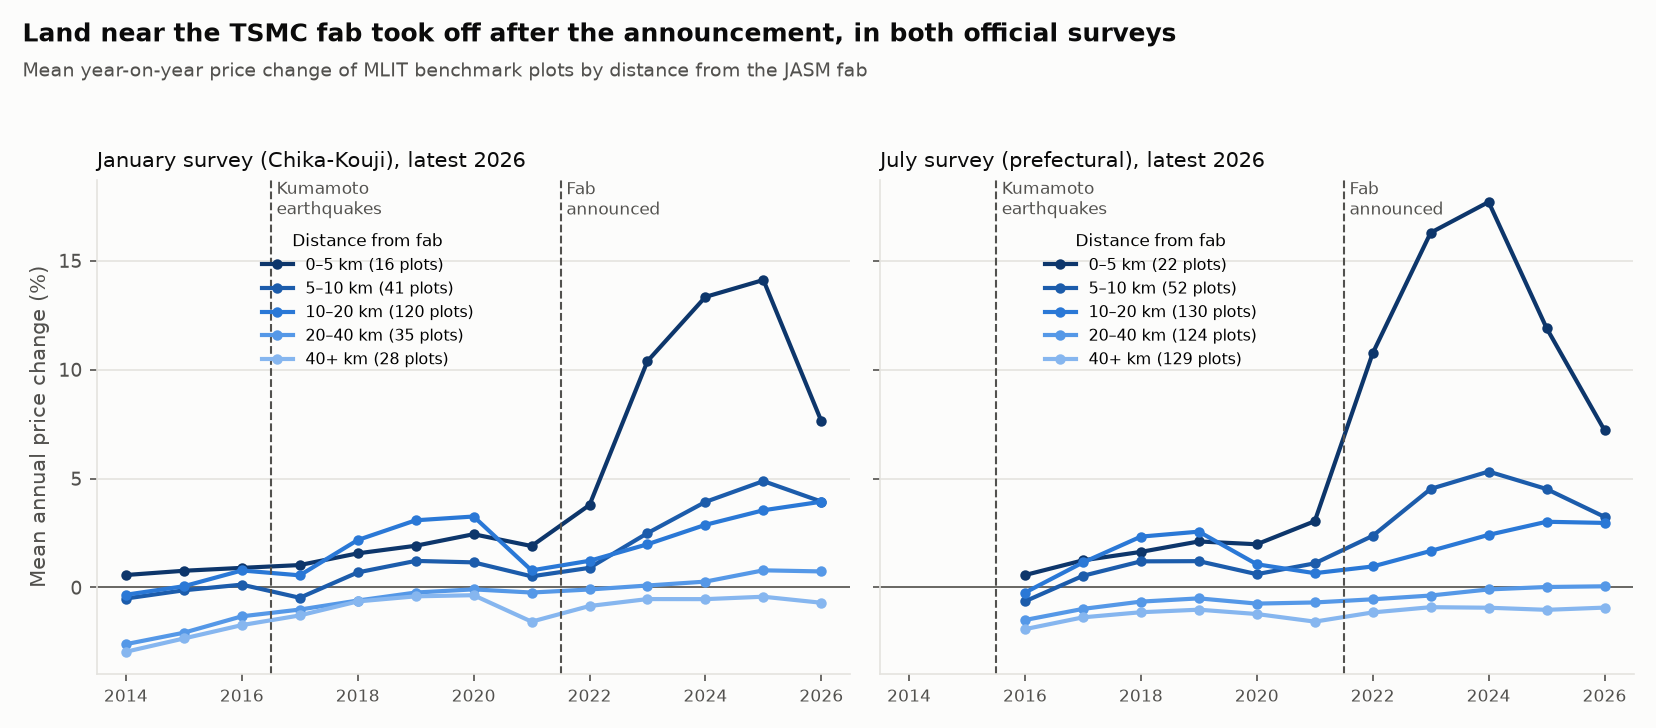

In [2]:
display(Image(filename=fab_impact.BANDS_FIGURE))

## 2. How big is the effect, and how far does it reach?

Prices were rising in many places, so a chart alone cannot show how much of the rise is due to the fab. The estimate below compares each plot with **its own pre-announcement trend** and with **the market in the same survey and year**. What remains is the extra growth linked to being near the fab. The bars show that extra growth per year since 2022, with 95% confidence ranges, using both surveys.

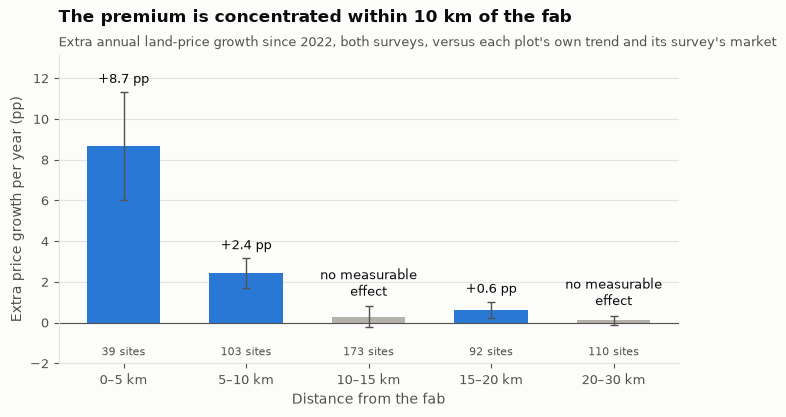

In [3]:
fig, ax = plot_style.figure(8, 4)
significant = rings["p_value"] < 0.05
colors = [plot_style.SERIES if s else "#b4b2ab" for s in significant]
ax.bar(rings["ring"], rings["estimate_pp"], color=colors, width=0.6,
       yerr=[rings["estimate_pp"] - rings["ci_low"], rings["ci_high"] - rings["estimate_pp"]],
       error_kw={"ecolor": plot_style.TEXT_SECONDARY, "elinewidth": 1, "capsize": 3})
ax.axhline(0, color=plot_style.TEXT_SECONDARY, linewidth=0.8)
for x, (est, high, sig, n) in enumerate(zip(rings["estimate_pp"], rings["ci_high"], significant, rings["n_sites"])):
    label = f"{est:+.1f} pp" if sig else "no measurable\neffect"
    ax.text(x, max(high, 0) + 0.3, label, ha="center", va="bottom", fontsize=9, color=plot_style.TEXT)
    ax.text(x, -1.6, f"{n} sites", ha="center", fontsize=8, color=plot_style.TEXT_SECONDARY)
ax.set_ylim(-2, rings["ci_high"].max() + 1.8)
ax.set_ylabel("Extra price growth per year (pp)")
ax.set_xlabel("Distance from the fab")
plot_style.title(ax, "The premium is concentrated within 10 km of the fab",
                 "Extra annual land-price growth since 2022, both surveys, versus each plot's own trend and its survey's market")

**Two independent surveys agree.** The January and July surveys use different plots and different appraisers. Each shows the effect on its own, and the checks below change the estimate little.

In [4]:
rows = [did["main"]] + did["by_survey"] + did["robustness"]
table = pd.DataFrame(rows)[["label", "estimate_pp", "ci_low", "ci_high", "n_near_sites"]]
(table.set_index("label").rename_axis("Within 10 km unless stated")
      .style.format({"estimate_pp": "{:+.1f} pp", "ci_low": "{:+.1f}", "ci_high": "{:+.1f}", "n_near_sites": "{:d}"})
      .relabel_index(["Extra growth per year", "95% range from", "to", "Sites near the fab"], axis=1))

,Extra growth per year,95% range from,to,Sites near the fab
Within 10 km unless stated,,,,
"Main: within 10 km, both surveys",+3.7 pp,+2.7,+4.7,142
January survey (L01) only,+3.0 pp,+1.9,+4.2,65
July survey (L02) only,+4.3 pp,+2.8,+5.8,87
Within 5 km,+8.1 pp,+5.5,+10.8,39
Within 15 km,+1.7 pp,+1.1,+2.3,315
Pre-period from 2018 (after the earthquake dip),+3.8 pp,+2.8,+4.8,141
Excluding Kumamoto City,+5.2 pp,+3.7,+6.8,83
Excluding the 2021 valuation,+3.9 pp,+2.9,+4.9,142


**Is it really the fab?** The check is whether plots near and far from the fab were already moving apart *before* the announcement. The chart compares near plots (within 10 km) with the rest, year by year, relative to 2021.

- Before the April 2016 earthquakes (2014–2015), near and far plots moved together.
- For five years after the earthquakes, whose epicentre was next to the fab towns, near plots ran about 1 point a year behind the rest.
- By 2021 they were back level, and from 2022 they pulled ahead, by up to 5 points a year (7 outside Kumamoto City).

The jump after 2022 is several times larger than anything before it. Because the comparison includes the depressed post-earthquake years, the estimates above are, if anything, on the conservative side.

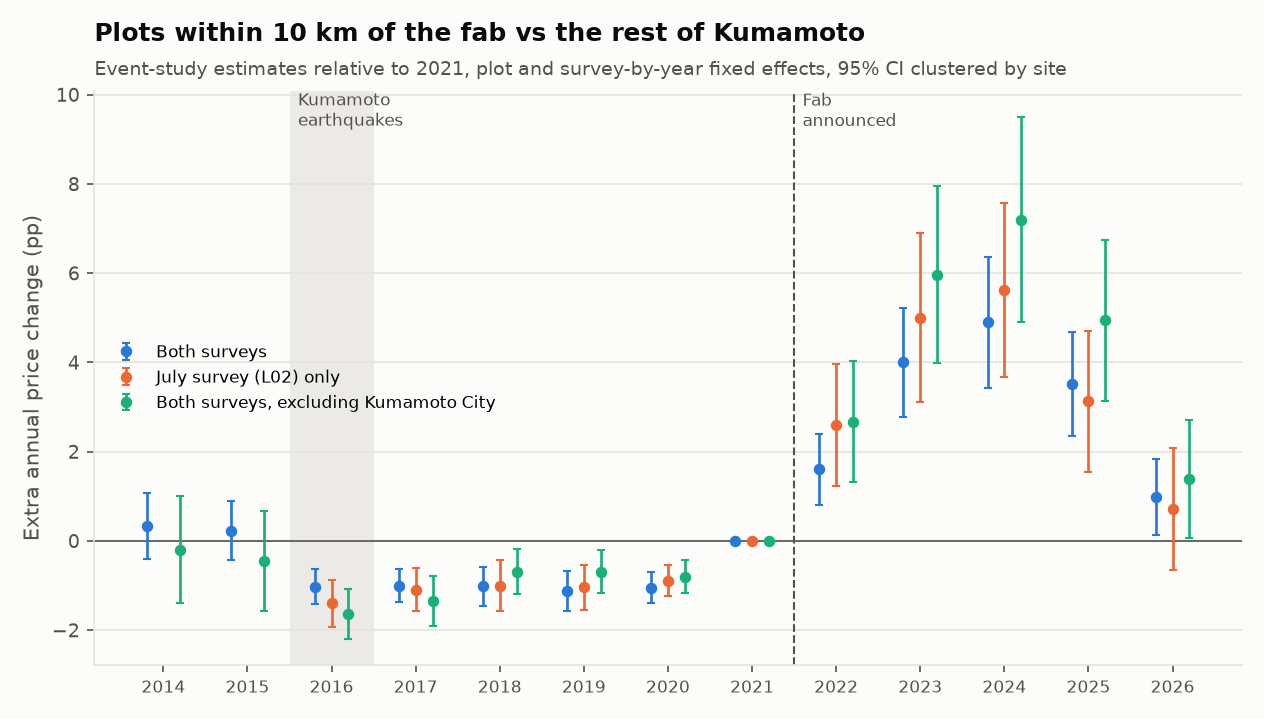

In [5]:
display(Image(filename=fab_impact.EVENT_STUDY_FIGURE))

## 3. Who gained, and by how much

Median price change from the 2021 valuation (the last before the announcement) to 2026, for each municipality with at least three benchmark sites. Bars in blue are towns whose sites are mostly within 10 km of the fab.

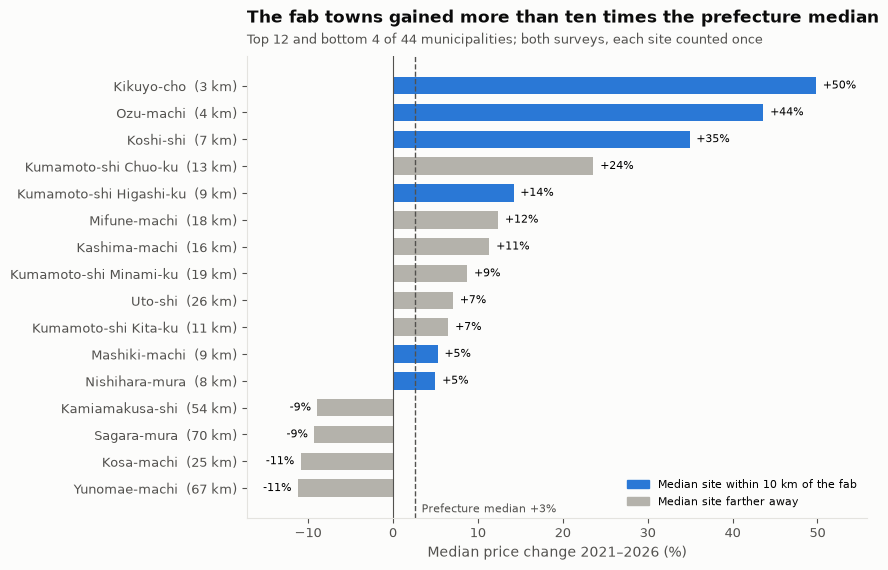

In [6]:
towns = (cum.groupby("municipality")
         .agg(plots=("cum_change", "size"), change=("cum_change", "median"), km=("distance_to_jasm_km", "median"))
         .query("plots >= 3").sort_values("change"))
prefecture = cum["cum_change"].median()
shown = pd.concat([towns.tail(12), towns.head(4)]).drop_duplicates().sort_values("change")

fig, ax = plot_style.figure(8, 6)
colors = [plot_style.SERIES if km <= 10 else "#b4b2ab" for km in shown["km"]]
ax.barh([f"{m}  ({km:.0f} km)" for m, km in zip(shown.index, shown["km"])], shown["change"], color=colors, height=0.65)
ax.axvline(prefecture, color=plot_style.TEXT_SECONDARY, linestyle="--", linewidth=1)
ax.text(prefecture + 0.8, -0.9, f"Prefecture median {prefecture:+.0f}%", fontsize=8, color=plot_style.TEXT_SECONDARY)
for y, v in enumerate(shown["change"]):
    ax.text(v + (0.8 if v >= 0 else -0.8), y, f"{v:+.0f}%", va="center", ha="left" if v >= 0 else "right", fontsize=8)
ax.axvline(0, color=plot_style.TEXT_SECONDARY, linewidth=0.8)
ax.set_xlim(shown["change"].min() - 6, shown["change"].max() + 6)
ax.grid(axis="y", visible=False)
ax.legend(handles=[Patch(color=plot_style.SERIES, label="Median site within 10 km of the fab"),
                   Patch(color="#b4b2ab", label="Median site farther away")],
          frameon=False, fontsize=8, loc="lower right")
ax.set_xlabel("Median price change 2021–2026 (%)")
plot_style.title(ax, "The fab towns gained more than ten times the prefecture median",
                 f"Top 12 and bottom 4 of {len(towns)} municipalities; both surveys, each site counted once")

**In yen.** Residential sites only, so that shops and offices in city centres do not skew the comparison. "Change for a 250 m² lot" scales the typical change per m² to a plot of roughly median size.

In [7]:
res = cum[cum["land_use"] == "residential"].copy()
res["ring"] = pd.cut(res["distance_to_jasm_km"], [0, 5, 10, 20, 40, 200], labels=RING_LABELS)
res["yen_change"] = res["price_last"] - res["price_first"]
yen = res.groupby("ring", observed=True).agg(
    plots=("cum_change", "size"),
    price_2021=("price_first", "median"),
    price_2026=("price_last", "median"),
    change_pct=("cum_change", "median"),
    yen_per_m2=("yen_change", "median"),
)
yen["lot_250"] = yen["yen_per_m2"] * 250
(yen.rename_axis("Distance from fab")
    .style.format({"price_2021": "¥{:,.0f}", "price_2026": "¥{:,.0f}", "change_pct": "{:+.0f}%",
                   "yen_per_m2": lambda v: f"{'+' if v >= 0 else '−'}¥{abs(v):,.0f}",
                   "lot_250": lambda v: f"{'+' if v >= 0 else '−'}¥{abs(v) / 1e6:.1f}M"})
    .relabel_index(["Sites", "Median ¥/m² 2021", "Median ¥/m² 2026", "Median change",
                    "Median change ¥/m²", "Change for a 250 m² lot"], axis=1))

,Sites,Median ¥/m² 2021,Median ¥/m² 2026,Median change,Median change ¥/m²,Change for a 250 m² lot
Distance from fab,,,,,,
0–5 km,18,"¥50,550","¥66,300",+41%,"+¥19,000",+¥4.8M
5–10 km,60,"¥47,250","¥57,250",+14%,"+¥7,650",+¥1.9M
10–20 km,146,"¥61,000","¥64,000",+9%,"+¥4,200",+¥1.1M
20–40 km,104,"¥13,400","¥13,150",-0%,−¥50,−¥0.0M
40+ km,104,"¥11,700","¥11,100",-5%,−¥500,−¥0.1M


Across all land uses, the median site within 10 km gained about 18.5% from 2021 to 2026, against about 0.5% farther away. Residential sites 10–20 km away (mostly Kumamoto City) rose by about 9%, but the analysis in section 2 shows that this growth was largely Kumamoto City's own trend: the extra growth attributable to the fab at that distance is at most about half a point a year.

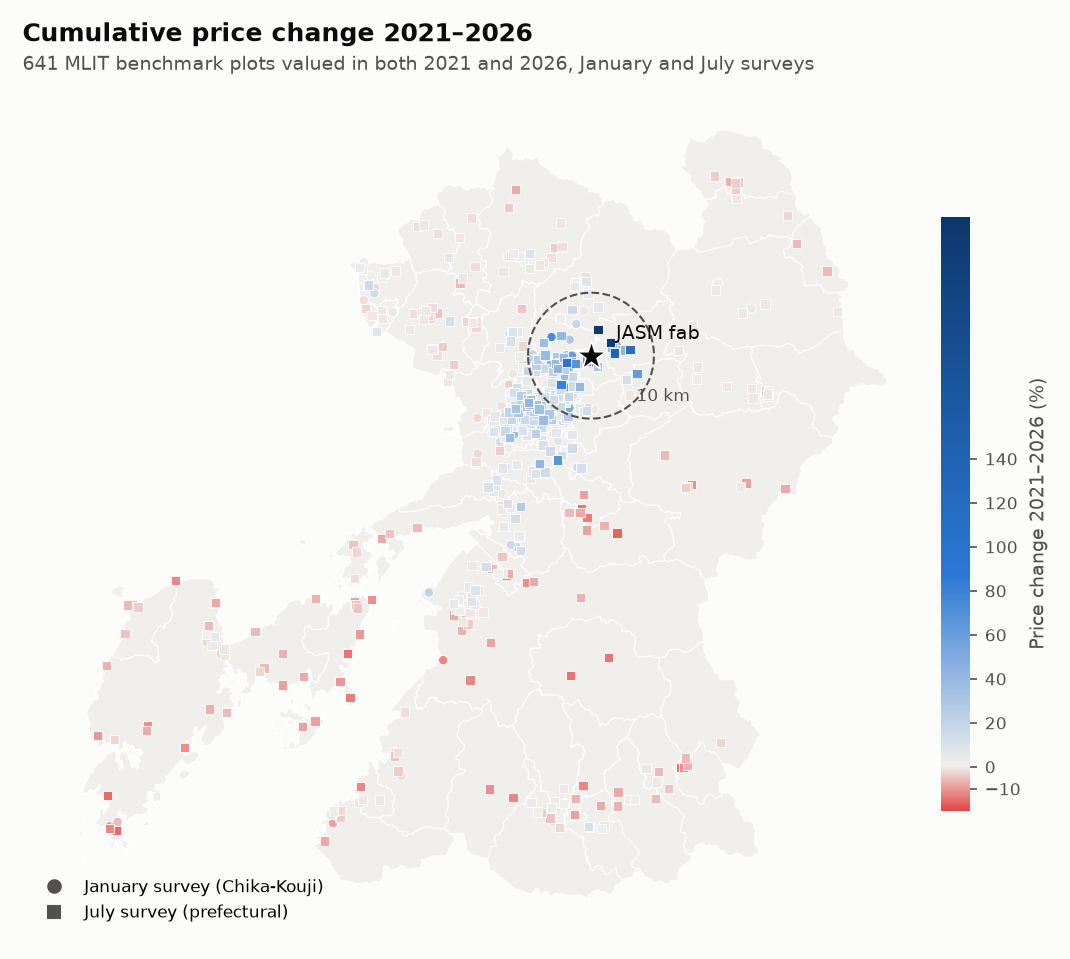

In [8]:
display(Image(filename=fab_impact.MAP_FIGURE))

## 4. Latest reading: the boom is cooling

The July 2026 prefectural survey is the newest official data, six months after the January survey. Growth within 5 km of the fab has now slowed for two readings in a row, in both surveys. In the July survey, the 2026 gap between near and far plots (+0.7 points a year) is no longer statistically significant.

In [9]:
recent = bands[bands["year"] >= 2023].pivot_table(index="band", columns=["survey", "year"], values="mean_pct_change")
recent = recent.reindex(RING_LABELS)
recent.columns = [f"{'Jan' if s == 'L01' else 'Jul'} {y}" for s, y in recent.columns]
recent = recent[sorted(recent.columns, key=lambda c: (int(c[-4:]), c.startswith("Jul")))]
recent.rename_axis("Distance from fab").style.format("{:+.1f}%")

,Jan 2023,Jul 2023,Jan 2024,Jul 2024,Jan 2025,Jul 2025,Jan 2026,Jul 2026
Distance from fab,,,,,,,,
0–5 km,+10.4%,+16.3%,+13.3%,+17.7%,+14.1%,+11.9%,+7.6%,+7.2%
5–10 km,+2.5%,+4.5%,+3.9%,+5.3%,+4.9%,+4.5%,+3.9%,+3.2%
10–20 km,+2.0%,+1.7%,+2.9%,+2.4%,+3.5%,+3.0%,+3.9%,+3.0%
20–40 km,+0.1%,-0.4%,+0.3%,-0.1%,+0.8%,+0.0%,+0.7%,+0.1%
40+ km,-0.5%,-0.9%,-0.5%,-0.9%,-0.4%,-1.0%,-0.7%,-0.9%


Whether this is a plateau, a pause before the planned second fab, or the start of a correction cannot be read from appraisals alone (see the plan in section 8).

## 5. Flood exposure in the growth zone

Planners will want to know whether the fastest-appreciating land, and the development it attracts, sits in flood-prone areas. Using MLIT's flood-inundation zones, the sites near the fab are mostly on higher ground; flood exposure is concentrated in Kumamoto City.

In [10]:
latest = stage2.sort_values("valuation_year").groupby("site_id").last()
latest["ring"] = pd.cut(latest["distance_to_jasm_km"], [0, 5, 10, 20, 40, 200], labels=RING_LABELS)
flood = latest.groupby("ring", observed=True).agg(sites=("flood_risk_class", "size"),
                                                  in_flood_zone=("flood_risk_class", lambda s: (s > 0).sum()))
flood["share"] = flood["in_flood_zone"] / flood["sites"]
(flood.rename_axis("Distance from fab")
      .style.format({"share": "{:.0%}"})
      .relabel_index(["Sites", "In a mapped flood zone", "Share"], axis=1))

,Sites,In a mapped flood zone,Share
Distance from fab,,,
0–5 km,39,1,3%
5–10 km,103,8,8%
10–20 km,265,134,51%
20–40 km,191,52,27%
40+ km,189,50,26%


Caveat: the flood layer is MLIT's FY2012 edition, and benchmark sites are a sample of locations, not every new development site. Updating the layer is a quick item in the plan.

## 6. What the forecasting models can and cannot do

The project also trained machine-learning models (Random Forest and XGBoost) on the January survey to predict each plot's price change, and tested them on the July survey's plots, which they never saw.

- **Forecasting the next year:** neither model beat the rule "this year's change will equal last year's", in either survey. The models learned the 2022–2024 acceleration and missed the slowdown.
- **Filling gaps between plots** (same years, unseen plots): the models make fewer large misses than the rule (higher R²). On the July survey's plots, however, their *typical* miss is slightly larger (0.8 against 0.75 points).

In [11]:
pick = {"forecast": "Forecast 2025–26, January survey", "external_l02_forecast": "Forecast 2025–26, July survey",
        "unseen_plots": "Unseen plots, January survey", "external_l02": "Unseen plots, July survey"}
rows = ["Persistence (last year's change)", "Random Forest", "XGBoost"]
sub = comparison[comparison["split"].isin(pick)].assign(test=lambda d: d["split"].map(pick))
mae = sub.pivot(index="model", columns="test", values="mae").loc[rows, list(pick.values())]
mae.index = ["Rule: same as last year", "Random Forest", "XGBoost"]
mae.rename_axis("Average miss (pp)").style.format("{:.2f}").highlight_min(axis=0, props="font-weight: bold")

test,"Forecast 2025–26, January survey","Forecast 2025–26, July survey","Unseen plots, January survey","Unseen plots, July survey"
Average miss (pp),,,,
Rule: same as last year,0.98,0.72,0.96,0.75
Random Forest,1.22,1.11,0.88,0.83
XGBoost,1.16,1.21,0.87,0.79


**Practical meaning:** do not use this project's models to forecast next year's land prices. Last year's change is as good a guide as anything here, and it misses turning points. Better forecasts need leading indicators such as transaction volumes, building permits and population inflows, not a more complex model on the same data.

## 7. What this means for decisions

**Prefecture and municipal planners**
- The fab's price pressure is concentrated in Kikuyo, Ozu and Koshi and fades out by about 10 km. Housing-affordability and infrastructure measures aimed at the fab's effects can be targeted there rather than prefecture-wide.
- Kumamoto City's rise is mostly its own trend, not a fab spillover.
- Outside the Kumamoto–fab corridor, median prices are falling in half of the municipalities with enough sites to judge. The fab has not changed that.
- The appreciation zone is largely outside mapped flood areas, which is reassuring for development that follows it. This should be re-checked with current flood maps.

**Landowners and developers**
- The premium is very local. Being 5 km or 15 km from the fab makes a large difference.
- Growth near the fab has slowed for two readings in a row. Past momentum is not a reliable guide to the next few years.

**Investors**
- The analysis measures what has happened; it does not provide a price forecast, and nothing here is investment advice. The evidence is consistent with a one-off repricing of land near the fab that is now fading, rather than a steady trend.

## How much to trust these numbers

- **Data accuracy:** the price changes computed here match MLIT's own published change rates exactly for all 3,950 plot-years where MLIT publishes one (1,216 in the January survey, 2,734 in the July survey).
- **Two independent sources:** the January and July surveys use different plots and appraisers, and both show the effect. About 25 sites are valued by both; they are counted once.
- **Benchmark prices are expert appraisals, not sale prices.** Appraisals react to the market with a lag and smooth it, so real transaction prices near the fab may have moved more, and earlier.
- **Still a modest number of sites near the fab:** 39 sites within 5 km across both surveys, so the 5 km figures have ranges of about ±3 points a year.
- **"The fab" means the fab and everything that followed it:** suppliers, housing demand, road projects and expectations about the second fab are all part of the measured effect.

## 8. Making the project more valuable: plan

**Where the value is today:** a validated, reproducible measurement of how much and how far the fab moved land prices, from two independent official surveys, refreshed twice a year.

**Where it falls short:** appraisal values that lag the market, no view of who is affected (renters, households), and no forecasting value.

| # | Work | What it adds for stakeholders | Status / effort | Needs |
|---|---|---|---|---|
| 1 | **Add the prefectural land price survey** (都道府県地価調査) | About twice as many plots near the fab, an independent replication of the effect, and a July reading six months after each January one | **Done** | — |
| 2 | **Twice-yearly refresh and monitor** | One command after each March (January survey) and September (July survey) release updates every figure and the dashboard, with a short "what changed" summary per distance ring | 1 day | Nothing new |
| 3 | **Update the flood layer** to MLIT's current flood-inundation maps, and add landslide and liquefaction exposure for the growth zone | A current hazard check on where the fab is pulling development | 0.5–1 day | Nothing new |
| 4 | **Add actual transaction prices** (MLIT Real Estate Information Library API) | Real sale prices and deal volumes, quarterly. Shows whether the market is running ahead of appraisals and gives an earlier read on the slowdown | 2–3 days | Free API key |
| 5 | **Add housing and population data** (e-Stat: rents, household inflows by municipality) | An affordability and displacement view: who is being priced out, and where | 3–5 days | Free app ID |
| 6 | **Separate the first fab from the second** (announced in February 2024) | Whether the 2024–2026 valuations already price in the second fab, and what remains to come | Needs item 4 first | — |

**Recommended next step:** items 2 and 3. They need no new accounts, take about two days together, and turn the current analysis into a monitor that updates with each MLIT release.

**What not to invest in:** more complex price-forecasting models on appraisal data alone. Section 6 shows, on two surveys, that the data does not support it. Forecasting becomes worthwhile only after transaction and population data (items 4–5) supply leading indicators.